# A multiplicative MMM with mixed dimensions

Build one media mix model for 10 products sold at 5 retailers.
Each input is measured at a different level:

| Input | Measured by | Response |
| --- | --- | --- |
| TV, social, video | product type × retailer | adstock, then saturation |
| Search | product type | adstock, then saturation |
| Two affiliate channels | product type × retailer | adstock only |
| Price and promotion | product × retailer | linear |

The target is log sales by product and retailer, so the effects multiply on the sales scale.

Build the model in small steps.
Each step adds one idea.
The finished model has 355 parameters and fits 50 sales series together.
The last section writes all of it as one short function of 14 statements.

Read [Introduction to terms](introduction_terms.ipynb) first.
Run the cells in order.
All data are simulated in this notebook.

> **Warning:** This API is experimental and its interfaces can change.
> The stable `MMM` class is unchanged.

## 1. Describe the panel

Ten products are sold at five retailers.
Each product belongs to one of three product types.

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from pymc_extras.prior import Prior

az.style.use("arviz-darkgrid")
plt.rcParams["figure.figsize"] = [12, 7]
plt.rcParams["figure.dpi"] = 100

rng = np.random.default_rng(42)

In [2]:
products = [f"product_{i:02d}" for i in range(1, 11)]
retailers = [f"retailer_{i}" for i in range(1, 6)]
product_types = ["type_A", "type_B", "type_C"]

Record the type of each product.

In [3]:
product_type = pd.Series(
    ["type_A"] * 4 + ["type_B"] * 3 + ["type_C"] * 3,
    index=pd.Index(products, name="product"),
    name="product_type",
)
product_type.to_frame().T

product,product_01,product_02,product_03,product_04,product_05,product_06,product_07,product_08,product_09,product_10
product_type,type_A,type_A,type_A,type_A,type_B,type_B,type_B,type_C,type_C,type_C


Start an empty dataset with the labels of every dimension.
The data are weekly, for three years.
Saturating media and affiliates have separate channel dimensions, because they will get different response functions.

In [4]:
dataset = xr.Dataset(
    coords={
        "date": pd.date_range("2023-01-02", periods=156, freq="W-MON"),
        "product": products,
        "retailer": retailers,
        "product_type": product_types,
        "media_channel": ["tv", "social", "video"],
        "affiliate_channel": ["affiliate_1", "affiliate_2"],
        "control": ["log_price_ratio", "promotion"],
    }
)

## 2. Keep each input at its own level

Store each input with the dimensions it is measured at.
Do not copy media spend to every product, and do not split it between products.

Simulate weekly spend in thousands.
The values are already on a small scale; terms do not scale data automatically.
The helper takes the dimensions of one input.

In [5]:
def simulate_spend(*dims: str) -> xr.DataArray:
    """Draw weekly spend with the given dimensions; some weeks have none."""
    shape = [dataset.sizes[dim] for dim in dims]
    spend = rng.uniform(0, 1, shape) * (rng.random(shape) > 0.35)
    return xr.DataArray(spend, dims=dims)

Media and affiliates are bought by product type and retailer.
Search is bought by product type only.

In [6]:
dataset["media_spend"] = simulate_spend(
    "date", "product_type", "retailer", "media_channel"
)
dataset["search_spend"] = simulate_spend("date", "product_type")
dataset["affiliate_spend"] = simulate_spend(
    "date", "product_type", "retailer", "affiliate_channel"
)

Controls are measured by product and retailer.
Use the log of price over a reference price, and a promotion flag centered on its average rate.

In [7]:
control_shape = [dataset.sizes[dim] for dim in ("date", "product", "retailer")]
log_price_ratio = rng.normal(0, 0.12, control_shape)
promotion = rng.binomial(1, 0.25, control_shape) - 0.25
dataset["controls"] = (
    ("date", "product", "retailer", "control"),
    np.stack([log_price_ratio, promotion], axis=-1),
)

One more input links the two levels.
The membership table has one row per product, with a 1 under its type.
Step 5.6 uses it.

In [8]:
dataset["membership"] = xr.DataArray(
    pd.get_dummies(product_type, dtype=float), dims=("product", "product_type")
)
dataset["membership"].to_pandas().astype(int)

product_type,type_A,type_B,type_C
product,,,
product_01,1,0,0
product_02,1,0,0
product_03,1,0,0
product_04,1,0,0
product_05,0,1,0
product_06,0,1,0
product_07,0,1,0
product_08,0,0,1
product_09,0,0,1


## 3. Model log sales to make the effects multiply

The target is the log of sales.
The model adds effects on that scale:

$$
\log(\text{sales}) = \text{baseline} + \text{media} + \text{search} + \text{affiliates} + \text{controls} + \text{noise}.
$$

Take the exponential of both sides.
The exponential of a sum is a product:

In [9]:
print(f"{np.exp(0.3 + 0.2):.4f} = {np.exp(0.3) * np.exp(0.2):.4f}")

1.6487 = 1.6487


So the same model is a product on the sales scale:

$$
\text{sales} = e^{\text{baseline}} \times e^{\text{media}} \times e^{\text{search}} \times e^{\text{affiliates}} \times e^{\text{controls}} \times e^{\text{noise}}.
$$

Every block in this notebook is a log effect.
A `+` between two blocks multiplies sales by one more factor.
A log effect of 0.10 multiplies sales by `exp(0.10)`, about 1.105: a 10.5% lift on top of the other factors.

## 4. Simulate sales from this process

Draw true coefficients, calculate each log effect with plain xarray, and take the exponential.
Skim the collapsed cells if you only want the model: section 5 writes the same structure with terms.
Section 9 uses the true effects again.

In [10]:
def draw(low: float, high: float, *dims: str) -> xr.DataArray:
    """Draw true coefficients with the given dimensions."""
    shape = [dataset.sizes[dim] for dim in dims]
    coords = {dim: dataset[dim] for dim in dims}
    return xr.DataArray(rng.uniform(low, high, shape), dims=dims, coords=coords)


def adstock(spend: xr.DataArray, alpha: xr.DataArray) -> xr.DataArray:
    """Carry spend over six weeks with normalized geometric weights."""
    weights = [alpha**lag for lag in range(6)]
    carried = sum(
        spend.shift(date=lag, fill_value=0) * weight
        for lag, weight in enumerate(weights)
    )
    return carried / sum(weights)


def saturation(spend: xr.DataArray, lam: xr.DataArray) -> xr.DataArray:
    """Apply the logistic saturation curve, which levels off at 1."""
    return np.tanh(lam * spend / 2)

Draw the true coefficients.
Each key is the name of the model parameter that estimates it.

In [11]:
media_level = ("product_type", "retailer", "media_channel")
affiliate_level = ("product_type", "retailer", "affiliate_channel")
truth = {
    "media_adstock_alpha": draw(0.2, 0.5, *media_level),
    "media_saturation_lam": draw(2.0, 4.0, *media_level),
    "media_saturation_beta": draw(0.15, 0.35, *media_level),
    "search_adstock_alpha": draw(0.1, 0.3, "product_type"),
    "search_saturation_lam": draw(2.0, 4.0, "product_type"),
    "search_saturation_beta": draw(0.15, 0.30, "product_type"),
    "affiliate_adstock_alpha": draw(0.1, 0.4, *affiliate_level),
    "affiliate_beta": draw(0.10, 0.25, *affiliate_level),
    "control_beta": xr.concat(
        [
            draw(-1.3, -0.7, "product", "retailer"),
            draw(0.15, 0.30, "product", "retailer"),
        ],
        dim=dataset["control"],
    ),
    "log_baseline": draw(np.log(80), np.log(140), "product", "retailer"),
}

Calculate the true log effect of each block at its own level.

In [12]:
true_effect = {
    "media": truth["media_saturation_beta"]
    * saturation(
        adstock(dataset["media_spend"], truth["media_adstock_alpha"]),
        truth["media_saturation_lam"],
    ),
    "search": truth["search_saturation_beta"]
    * saturation(
        adstock(dataset["search_spend"], truth["search_adstock_alpha"]),
        truth["search_saturation_lam"],
    ),
    "affiliates": truth["affiliate_beta"]
    * adstock(dataset["affiliate_spend"], truth["affiliate_adstock_alpha"]),
    "controls": (dataset["controls"] * truth["control_beta"]).sum("control"),
}

Add the effects on the log scale, add noise, and take the exponential to get sales.

In [13]:
true_type_effect = (
    true_effect["media"].sum("media_channel")
    + true_effect["search"]
    + true_effect["affiliates"].sum("affiliate_channel")
)
true_log_mu = (
    truth["log_baseline"]
    + (true_type_effect * dataset["membership"]).sum("product_type")
    + true_effect["controls"]
).transpose("date", "product", "retailer")
sales = np.exp(true_log_mu + rng.normal(0, 0.08, true_log_mu.shape))

The model never sees `sales`.
Take the log to make its target.
This one line makes the model multiplicative.

In [14]:
dataset["log_sales"] = np.log(sales)

The dataset is complete.
Each variable keeps its own dimensions.
Only `controls` and `log_sales` have the product × retailer layout.

In [15]:
pd.Series(
    {name: ", ".join(variable.dims) for name, variable in dataset.data_vars.items()},
    name="dimensions",
).to_frame()

,dimensions
media_spend,"date, product_type, retailer, media_channel"
search_spend,"date, product_type"
affiliate_spend,"date, product_type, retailer, affiliate_channel"
controls,"date, product, retailer, control"
membership,"product, product_type"
log_sales,"date, product, retailer"


## 5. Build the model one block at a time

Write the model for product $p$ of type $g(p)$, at retailer $r$, in week $t$:

$$
\log y_{t,p,r} = b_{p,r} + M_{t,g(p),r} + S_{t,g(p)} + A_{t,g(p),r} + C_{t,p,r} + \varepsilon_{t,p,r}.
$$

The subscripts show the level of each block.
Media $M$ and affiliates $A$ vary by product type and retailer.
Search $S$ varies by product type only.
The baseline $b$ and the controls $C$ vary by product and retailer.

A term describes one piece of this equation.
A term computes nothing when you define it.
Step 5.9 builds the model, when the terms meet the data.

### 5.1 Media: product type × retailer

Look at the input first.

In [16]:
dataset["media_spend"].dims

('date', 'product_type', 'retailer', 'media_channel')

`Data` refers to this variable by name.
It does not hold the values.

In [17]:
from pymc_marketing.experimental.terms import Data

media_spend = Data("media_spend")

Choose the adstock.
The effect of spend lasts six weeks (`l_max=6`): the week of the spend and the next five.
The `prefix` names the parameter: `media_adstock_alpha`.

In [18]:
from pymc_marketing.mmm import GeometricAdstock

media_adstock = GeometricAdstock(l_max=6, prefix="media_adstock")

Choose the saturation.
Its parameter `beta` is the largest log effect that one channel can reach.
The default prior, `HalfNormal(2)`, is too wide on the log scale: a log effect of 2 multiplies sales by more than 7.
Set a prior in log units.

In [19]:
from pymc_marketing.mmm import LogisticSaturation

media_saturation = LogisticSaturation(
    prefix="media_saturation",
    priors={"beta": Prior("HalfNormal", sigma=0.4)},
)

Chain the steps with `>>`: spend, then adstock, then saturation.
`.named` keeps the result in the posterior under that name.

In [20]:
media = (media_spend >> media_adstock >> media_saturation).named("media_log_effect")

You did not write any dimensions.
Each parameter takes the dimensions of the input other than `date`: one value per product type, retailer, and channel.

### 5.2 Search: product type only

Search has a smaller input.

In [21]:
dataset["search_spend"].dims

('date', 'product_type')

Write the same recipe as one expression.
The parameters now vary by product type only, because the input does.
Give search its own prefixes: two transformations cannot share parameter names.

In [22]:
search = (
    Data("search_spend")
    >> GeometricAdstock(l_max=6, prefix="search_adstock")
    >> LogisticSaturation(
        prefix="search_saturation",
        priors={"beta": Prior("HalfNormal", sigma=0.4)},
    )
).named("search_log_effect")

Do not copy search spend to every retailer.
Step 5.5 handles the missing dimension.

### 5.3 Affiliates: adstock, no saturation

The two affiliate channels are at the same level as media.

In [23]:
dataset["affiliate_spend"].dims

('date', 'product_type', 'retailer', 'affiliate_channel')

Stop the chain after adstock.

In [24]:
affiliate_adstocked = Data("affiliate_spend") >> GeometricAdstock(
    l_max=6, prefix="affiliate_adstock"
)

For media, the saturation supplied the effect size `beta`.
Without a saturation, add the effect size yourself.
A `Parameter` has a name and a prior.
It is not attached to an input, so it does not take dimensions from one.
State them in the prior; without `dims`, all the channels would share one coefficient.

In [25]:
from pymc_marketing.terms import Parameter

affiliate_dims = ("product_type", "retailer", "affiliate_channel")
affiliate_beta = Parameter(
    "affiliate_beta", Prior("HalfNormal", sigma=0.3, dims=affiliate_dims)
)

Multiply the two terms.
They align by dimension name.

In [26]:
affiliates = (affiliate_adstocked * affiliate_beta).named("affiliate_log_effect")

The log effect is a straight line in adstocked spend.
Sales are not: each extra unit of adstocked spend multiplies sales by the same factor.

### 5.4 Controls: product × retailer

Controls are measured at the level of sales.

In [27]:
dataset["controls"].dims

('date', 'product', 'retailer', 'control')

Give each product–retailer pair its own coefficient for each control.

In [28]:
control_beta = Parameter(
    "control_beta",
    Prior("Normal", mu=0, sigma=0.5, dims=("product", "retailer", "control")),
)

Multiply the controls by their coefficients, then add the two controls.
`.sum("control")` removes that dimension and no other.

In [29]:
controls = (Data("controls") * control_beta).sum("control")

The coefficient of the log price ratio is a price elasticity.

### 5.5 Add the media blocks by product type

Media, search, and affiliates are at the product-type level.
Add them at that level first.
Sum over each channel dimension, so that `date`, `product_type`, and `retailer` remain.

These are log effects.
Each `+` and each channel sum multiplies factors on the sales scale: TV × social × video × search × the two affiliates.

In [30]:
type_effect = media.sum("media_channel") + search + affiliates.sum("affiliate_channel")

Search has no `retailer` dimension, and you did not copy it.
Terms align by name, so each retailer receives the same search effect.

### 5.6 Move from product type to product

Sales are by product, not by product type.
The membership table moves a value from a type to the products of that type.
Try it with three numbers, one per type:

In [31]:
by_type = xr.DataArray([10.0, 20.0, 30.0], coords=[("product_type", product_types)])
(by_type * dataset["membership"]).sum("product_type").to_pandas().to_frame("value").T

product,product_01,product_02,product_03,product_04,product_05,product_06,product_07,product_08,product_09,product_10
value,10.0,10.0,10.0,10.0,20.0,20.0,20.0,30.0,30.0,30.0


Each product keeps the value of its own type.
The zeros in the table remove the other two types.

Do the same with the terms.

In [32]:
product_effect = (type_effect * Data("membership")).sum("product_type")

No spend was copied or divided.
The products of one type share one media response.

### 5.7 Add the pieces: `+` on the log scale is `×` on sales

One piece is missing: the baseline.
Each product–retailer pair has its own, on the log scale.
The prior is centered on `log(100)`: about 100 units per week before media and controls.

In [33]:
log_baseline = Parameter(
    "log_baseline",
    Prior("Normal", mu=np.log(100), sigma=0.6, dims=("product", "retailer")),
)

Add the three pieces.
`product_effect` holds the media, search, and affiliate blocks of section 3.

The code says `+` and the model multiplies, because step 5.8 makes this sum the mean of log sales.
On the sales scale the same line is a product: `exp(log_mu)` equals `exp(log_baseline) * exp(product_effect) * exp(controls)`.

In [34]:
log_mu = (log_baseline + product_effect + controls).named("log_mu")

### 5.8 Attach the likelihood

`Equation` connects the mean to the observed variable `log_sales`.
The model code has no `log` and no `exp` of the data: the log is in the target.
Use Normal noise on the log scale, with one noise parameter for all series.

In [35]:
from pymc_marketing.experimental.terms import SCM, Equation

model = SCM(
    Equation(
        observed="log_sales",
        mu=log_mu,
        likelihood=Prior("Normal", sigma=Prior("HalfNormal", sigma=0.2)),
    )
)

### 5.9 Build and inspect

Give the model the dataset.
Only this step makes PyMC variables.

In [36]:
model.build_model(dataset);

Show the model table.
Compare the dimensions of each parameter with the dimensions of its input.

In [37]:
from pymc_extras.printing import model_table

model_table(model.model)

                  Variable  Expression                                  Dimensions                                 
───────────────────────────────────────────────────────────────────────────────────────────────────────────────────
             media_spend =  Data                                        date[156] × product_type[3] × retailer[5]  
                                                                        × media_channel[3]                         
            search_spend =  Data                                        date[156] × product_type[3]                
         affiliate_spend =  Data                                        date[156] × product_type[3] × retailer[5]  
                                                                        × affiliate_channel[2]                     
              membership =  Data                                        product[10] × product_type[3]              
                controls =  Data                                        date[156] × product[10] × retailer[5] ×    
                                                                        control[2]                                 
                                                                                                                   
            log_baseline ~  Normal(4.61, 0.6)                           product[10] × retailer[5]                  
     media_adstock_alpha ~  Beta(1, 3)                                  product_type[3] × retailer[5] ×            
                                                                        media_channel[3]                           
    media_saturation_lam ~  Gamma(3, <constant>)                        product_type[3] × retailer[5] ×            
                                                                        media_channel[3]                           
   media_saturation_beta ~  HalfNormal(0, 0.4)                          product_type[3] × retailer[5] ×            
                                                                        media_channel[3]                           
    search_adstock_alpha ~  Beta(1, 3)                                  product_type[3]                            
   search_saturation_lam ~  Gamma(3, <constant>)                        product_type[3]                            
  search_saturation_beta ~  HalfNormal(0, 0.4)                          product_type[3]                            
 affiliate_adstock_alpha ~  Beta(1, 3)                                  product_type[3] × retailer[5] ×            
                                                                        affiliate_channel[2]                       
          affiliate_beta ~  HalfNormal(0, 0.3)                          product_type[3] × retailer[5] ×            
                                                                        affiliate_channel[2]                       
            control_beta ~  Normal(0, 0.5)                              product[10] × retailer[5] × control[2]     
         log_sales_sigma ~  HalfNormal(0, 0.2)                                                                     
                                                                        Parameter count = 355                      
                                                                                                                   
        media_log_effect =  f(media_saturation_beta,                    date[156] × product_type[3] × retailer[5]  
                            media_saturation_lam, media_adstock_alpha)  × media_channel[3]                         
       search_log_effect =  f(search_saturation_beta,                   date[156] × product_type[3]                
                            search_saturation_lam,                                                                 
                            search_adstock_alpha)                                                                  
    affiliate_log_effect =  f(affiliate_beta, affiliate_

Each block has the dimensions of its own input.
The media parameters vary by product type, retailer, and channel.
The search parameters vary by product type only.
The affiliates have an adstock parameter and an effect size, but no saturation parameters.
The baseline and the control coefficients vary by product and retailer.

The table counts 355 parameters.
One model covers the 50 product–retailer series.

The table shows `Unknown(...)` around the Normal likelihood.
This is a PyMC printing limitation, not a different likelihood.

## 6. Check the priors on the sales scale

A prior that looks narrow as a number can be wide in sales.
A width of 0.6 on the log scale is a factor of 1.8 in either direction.
Simulate sales from the priors, and compare their range with the data before you fit.

In [38]:
prior = model.sample_prior_predictive(
    dataset, draws=200, var_names=["log_sales"], random_seed=43
)
prior_sales = np.exp(prior["prior_predictive"]["log_sales"])

Sampling: [affiliate_adstock_alpha, affiliate_beta, control_beta, log_baseline, log_sales, log_sales_sigma, media_adstock_alpha, media_saturation_beta, media_saturation_lam, search_adstock_alpha, search_saturation_beta, search_saturation_lam]


In [39]:
quantiles = [0.03, 0.5, 0.97]
pd.DataFrame(
    {
        "prior predictive sales": np.quantile(prior_sales, quantiles),
        "observed sales": np.quantile(sales, quantiles),
    },
    index=["3%", "median", "97%"],
).round(1)

,prior predictive sales,observed sales
3%,47.2,106.0
median,185.2,177.1
97%,792.4,303.6


The two medians are close.
The prior range contains the observed range and is wider.
The priors leave room to learn from the data, and they do not give absurd sales.

## 7. Fit all the series together

Fit the 50 series in one model.
All the products of a type inform the media response of that type.

In [40]:
idata = model.fit(
    dataset,
    chains=4,
    tune=1_000,
    draws=1_000,
    target_accept=0.95,
    random_seed=44,
    progressbar=False,
)

NUTS[nutpie]: [log_baseline, media_adstock_alpha, media_saturation_lam, media_saturation_beta, search_adstock_alpha, search_saturation_lam, search_saturation_beta, affiliate_adstock_alpha, affiliate_beta, control_beta, log_sales_sigma]


Check the sampler before you read any result.
Look for zero divergences, a maximum R-hat below 1.01, and a large effective sample size.

In [41]:
free_parameters = [rv.name for rv in model.model.free_RVs]
posterior = idata["posterior"].to_dataset()[free_parameters]
pd.Series(
    {
        "divergences": int(idata["sample_stats"]["diverging"].sum()),
        "maximum R-hat": float(az.rhat(posterior).to_array().max()),
        "minimum bulk ESS": float(az.ess(posterior, method="bulk").to_array().min()),
    },
    name="value",
).round(3).to_frame()

,value
divergences,0.000
maximum R-hat,1.007
minimum bulk ESS,3092.358


## 8. Return to sales units

The three checks pass.
Predict log sales for the training weeks.

In [42]:
prediction = model.sample_posterior_predictive(
    dataset,
    var_names=["log_sales", "log_mu"],
    include_last_observations=False,
    random_seed=45,
    progressbar=False,
)

Sampling: [log_sales]


Take the exponential of each draw, not of a summary.
With Normal noise on the log scale, `exp(log_mu)` is the median of sales, not the mean.
The mean is larger by the factor `exp(sigma**2 / 2)`.

In [43]:
sigma = idata["posterior"]["log_sales_sigma"]
predicted_sales = np.exp(prediction["log_sales"])
mean_sales = np.exp(prediction["log_mu"] + sigma**2 / 2)

The factor is small in this example because the noise is small.

In [44]:
print(f"Mean over median: {float(np.exp(sigma**2 / 2).mean()):.4f}")

Mean over median: 1.0032


With a noise parameter of 0.5, the factor would be 1.13.

Plot one product of each type at the first retailer.
Each product combines the media response of its type with its own baseline and controls.
The band is a pointwise 94% predictive interval.

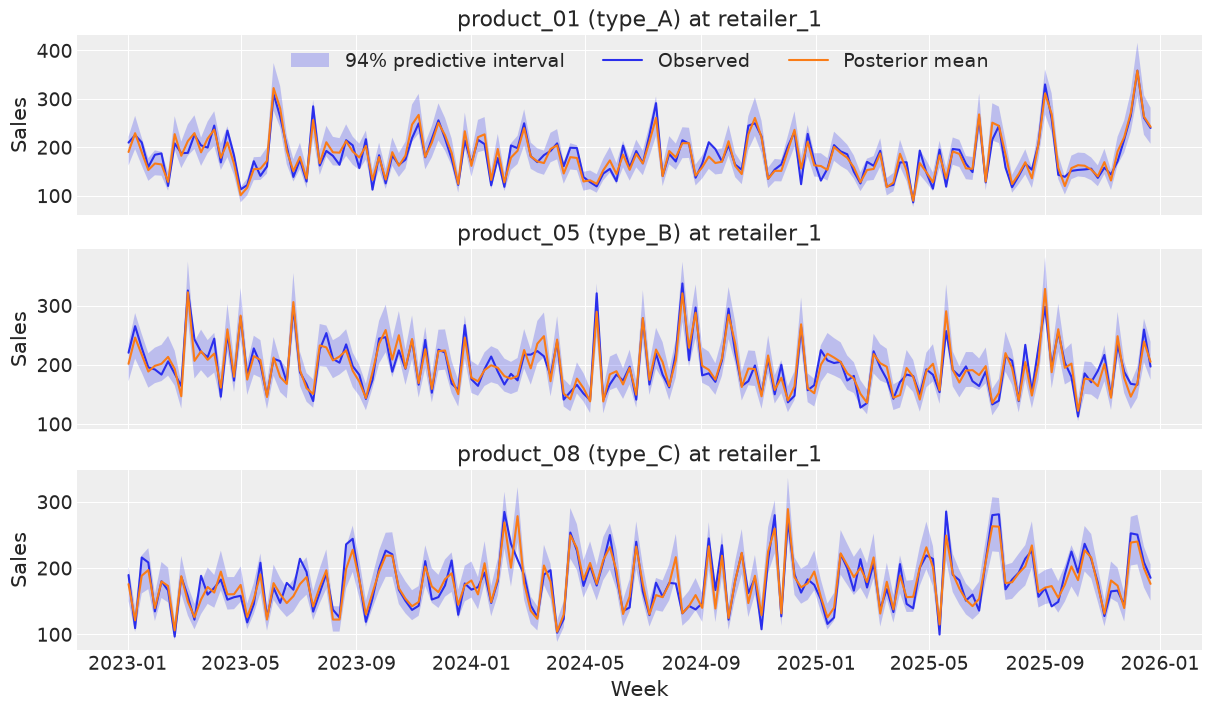

In [45]:
shown = ["product_01", "product_05", "product_08"]
at = {"product": shown, "retailer": "retailer_1"}
band = predicted_sales.sel(at).quantile([0.03, 0.97], dim=("chain", "draw"))
mean = mean_sales.sel(at).mean(("chain", "draw"))
weeks = dataset["date"].values
fig, axes = plt.subplots(3, 1, sharex=True, layout="constrained")
for ax, product in zip(axes, shown, strict=True):
    ax.fill_between(
        weeks,
        band.sel(product=product, quantile=0.03),
        band.sel(product=product, quantile=0.97),
        alpha=0.25,
        label="94% predictive interval",
    )
    ax.plot(weeks, sales.sel(product=product, retailer="retailer_1"), label="Observed")
    ax.plot(weeks, mean.sel(product=product), label="Posterior mean")
    ax.set(title=f"{product} ({product_type[product]}) at retailer_1", ylabel="Sales")
axes[0].legend(ncol=3)
axes[-1].set_xlabel("Week")
plt.show()

## 9. Read the effects as multipliers

The named log effects are in the posterior, at their own level.
Take the exponential of each draw to get a multiplier, then average over the weeks.
Search gives one multiplier per product type.
Compare it with the true value from section 4.

In [46]:
search_multiplier = np.exp(idata["posterior"]["search_log_effect"]).mean("date")
search_table = (
    search_multiplier.quantile([0.03, 0.5, 0.97], dim=("chain", "draw")).to_pandas().T
)
search_table["true"] = np.exp(true_effect["search"]).mean("date").to_pandas()
search_table.round(3)

quantile,0.03,0.5,0.97,true
product_type,,,,
type_A,1.112,1.120,1.128,1.118
type_B,1.106,1.115,1.124,1.124
type_C,1.135,1.143,1.152,1.146


A multiplier of 1.15 means that, in an average week, sales were 15% higher than with no search.
The same multiplier applies to each product of that type at each retailer.

Do the same for each media channel and each affiliate.
A point is one product type, retailer, and channel.

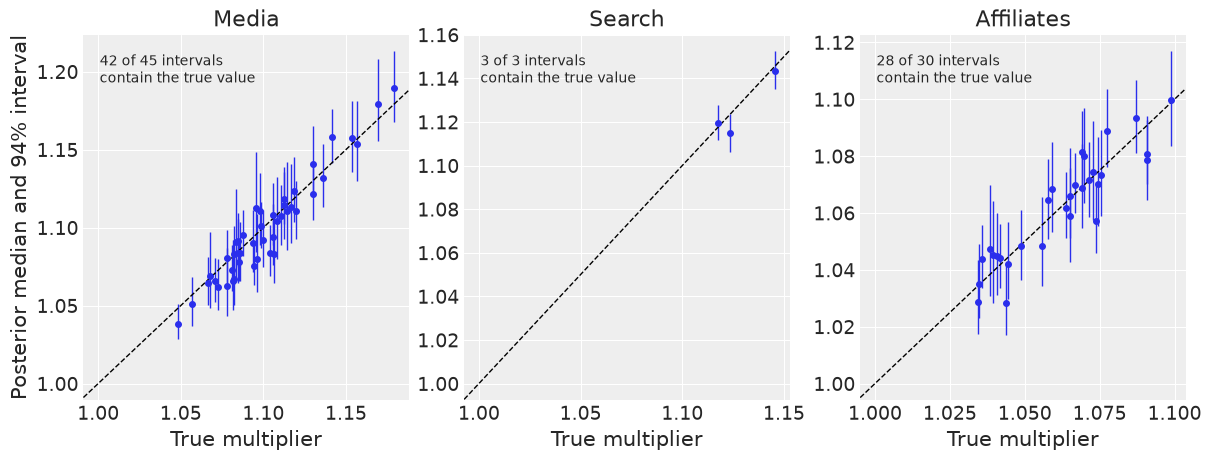

In [47]:
blocks = {
    "media": "media_log_effect",
    "search": "search_log_effect",
    "affiliates": "affiliate_log_effect",
}
fig, axes = plt.subplots(1, 3, figsize=(12, 4.5), layout="constrained")
for ax, (block, name) in zip(axes, blocks.items(), strict=True):
    true = np.exp(true_effect[block]).mean("date")
    estimate = (
        np.exp(idata["posterior"][name])
        .mean("date")
        .quantile([0.03, 0.5, 0.97], dim=("chain", "draw"))
        .stack(cell=true.dims)
    )
    true = true.stack(cell=true.dims).values
    lower, median, upper = estimate.values
    ax.errorbar(
        true, median, yerr=[median - lower, upper - median], fmt="o", ms=4, lw=1
    )
    ax.axline((1, 1), slope=1, color="black", ls="--", lw=1)
    covered = ((lower <= true) & (true <= upper)).sum()
    ax.set(title=block.capitalize(), xlabel="True multiplier")
    ax.text(
        0.05,
        0.95,
        f"{covered} of {true.size} intervals\ncontain the true value",
        transform=ax.transAxes,
        va="top",
    )
axes[0].set_ylabel("Posterior median and 94% interval")
plt.show()

The points lie along the diagonal.
Most intervals contain the true value, as 94% intervals should.

A multiplier is not a sales contribution or a return on spend.
To get the sales of one channel, compare predictions with and without that channel on the same posterior draws.
The [multiplicative walkthrough](terms_multiplicative_walkthrough.ipynb) shows how.

## 10. The whole model in one function

Section 5 added one idea per step.
Here are the same steps together.
The two saturations share one dictionary of priors; nothing else is new.

In [48]:
def mixed_dimension_mmm() -> SCM:
    """Return the multiplicative MMM for inputs at mixed dimensions."""
    effect_size = {"beta": Prior("HalfNormal", sigma=0.4)}
    media = (
        Data("media_spend")
        >> GeometricAdstock(l_max=6, prefix="media_adstock")
        >> LogisticSaturation(prefix="media_saturation", priors=effect_size)
    ).named("media_log_effect")
    search = (
        Data("search_spend")
        >> GeometricAdstock(l_max=6, prefix="search_adstock")
        >> LogisticSaturation(prefix="search_saturation", priors=effect_size)
    ).named("search_log_effect")

    affiliate_adstocked = Data("affiliate_spend") >> GeometricAdstock(
        l_max=6, prefix="affiliate_adstock"
    )
    affiliate_dims = ("product_type", "retailer", "affiliate_channel")
    affiliate_beta = Parameter(
        "affiliate_beta", Prior("HalfNormal", sigma=0.3, dims=affiliate_dims)
    )
    affiliates = (affiliate_adstocked * affiliate_beta).named("affiliate_log_effect")

    control_beta = Parameter(
        "control_beta",
        Prior("Normal", mu=0, sigma=0.5, dims=("product", "retailer", "control")),
    )
    controls = (Data("controls") * control_beta).sum("control")

    type_effect = (
        media.sum("media_channel") + search + affiliates.sum("affiliate_channel")
    )
    product_effect = (type_effect * Data("membership")).sum("product_type")
    log_baseline = Parameter(
        "log_baseline",
        Prior("Normal", mu=np.log(100), sigma=0.6, dims=("product", "retailer")),
    )
    log_mu = (log_baseline + product_effect + controls).named("log_mu")

    return SCM(
        Equation(
            observed="log_sales",
            mu=log_mu,
            likelihood=Prior("Normal", sigma=Prior("HalfNormal", sigma=0.2)),
        )
    )

Fourteen statements define 355 parameters for 50 sales series.
Each statement is one piece of the equation in section 5.
None states an array shape, loops over products, or copies spend.

Build it with the same dataset.
It defines the same model as section 5.
As a numerical check, evaluate the joint log-density of the two models at the same parameter values.

In [49]:
full_model = mixed_dimension_mmm()
full_model.build_model(dataset)
point = model.model.initial_point()  # one value for each parameter
stepwise_logp = model.model.compile_logp()(point)
function_logp = full_model.model.compile_logp()(point)
print(f"{stepwise_logp:.3f} = {function_logp:.3f}")

-8652.926 = -8652.926


Three rules do the work:

- **Dimensions come from the data.** A transformation gives its parameters the dimensions of its input, and a `Parameter` states its own. Each block stays at the level where it is measured.
- **Names align the pieces.** `+` and `*` match dimensions by name, `.sum(dim)` removes one of them, and the membership table moves effects from product type to product.
- **The scale sets the meaning.** With a log target, `+` multiplies sales, and the priors and effects are in log units.

A change to the case is a small change to the function, or none:

- If affiliates saturate, append `>> LogisticSaturation(prefix="affiliate_saturation", priors=effect_size)` to their chain and delete `affiliate_beta`.
- If search is bought by retailer, add `retailer` to `search_spend`. The function does not change.
- For a new product or retailer, add its label, its data, and its membership row. The function does not change.

Keep the limits in view.
The products of a type share one media response, and there is no partial pooling between product types or retailers.
The fit is in-sample, on simulated data with independent inputs.
It shows that the model can be written and recovered, not that effects are identified in observed data.

To forecast, supply the future inputs with the same membership table.
The [main experimental MMM example](experimental_mmm_api.ipynb) shows forecasts and budget plans.

In [50]:
%load_ext watermark
%watermark -n -u -v -iv -w -p pymc_marketing,pytensor

Last updated: Thu, 19 Nov 2026

Python implementation: CPython
Python version       : 3.14.0
IPython version      : 9.18.1

pymc_marketing: 1.5.0
pytensor      : 3.3.8

arviz         : 1.3.0
matplotlib    : 3.11.2
numpy         : 2.5.5
pandas        : 3.1.1
pymc_extras   : 0.16.0
pymc_marketing: 1.5.0
xarray        : 2026.9.0

Watermark: 2.6.0

